In [1]:
!pip install -q scikit-learn pandas matplotlib seaborn

In [3]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GroupShuffleSplit

df = sns.load_dataset("titanic")

df = df.dropna(subset=["survived"]).reset_index(drop=True)

print("Dataset Shape:", df.shape)
display(df.head())

X = df.drop("survived", axis=1)
y = df["survived"]

print("\nTarget Distribution:")
print(y.value_counts())
print(y.value_counts(normalize=True) * 100)

Dataset Shape: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True



Target Distribution:
survived
0    549
1    342
Name: count, dtype: int64
survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64


In [4]:
print(df["class"].value_counts())
print("\nTarget percentage:")
print(df["class"].value_counts(normalize=True) * 100)

class
Third     491
First     216
Second    184
Name: count, dtype: int64

Target percentage:
class
Third     55.106622
First     24.242424
Second    20.650954
Name: proportion, dtype: float64


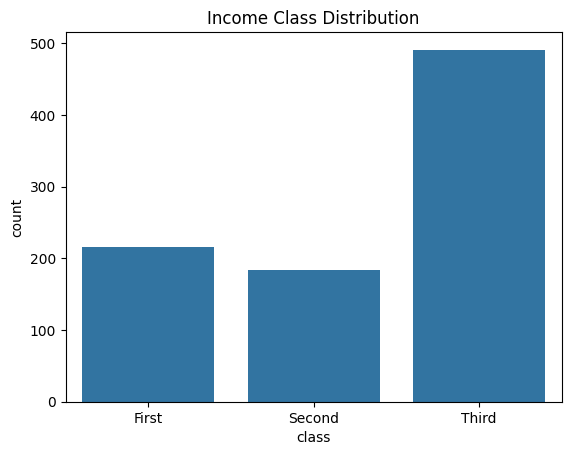

In [5]:
sns.countplot(data=df, x="class")
plt.title("Income Class Distribution")
plt.show()

# `Simple Random Sampling`

In [10]:
random_sample = df.sample(
    n=100,
    replace=False,
    random_state=42
)

display(random_sample.head())

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
709,1,3,male,NaN,1,1,15.2458,C,Third,man,True,NaN,Cherbourg,yes,False
439,0,2,male,31.0,0,0,10.5000,S,Second,man,True,NaN,Southampton,no,True
840,0,3,male,20.0,0,0,7.9250,S,Third,man,True,NaN,Southampton,no,True
720,1,2,female,6.0,0,1,33.0000,S,Second,child,False,NaN,Southampton,yes,False
39,1,3,female,14.0,1,0,11.2417,C,Third,child,False,NaN,Cherbourg,yes,False


# `Stratified Sampling`

In [11]:
stratified_sample = (
    df.groupby("survived", group_keys=False)
      .sample(frac=0.2, random_state=42)
)

print(stratified_sample["survived"].value_counts(normalize=True))

survived
0    0.617978
1    0.382022
Name: proportion, dtype: float64


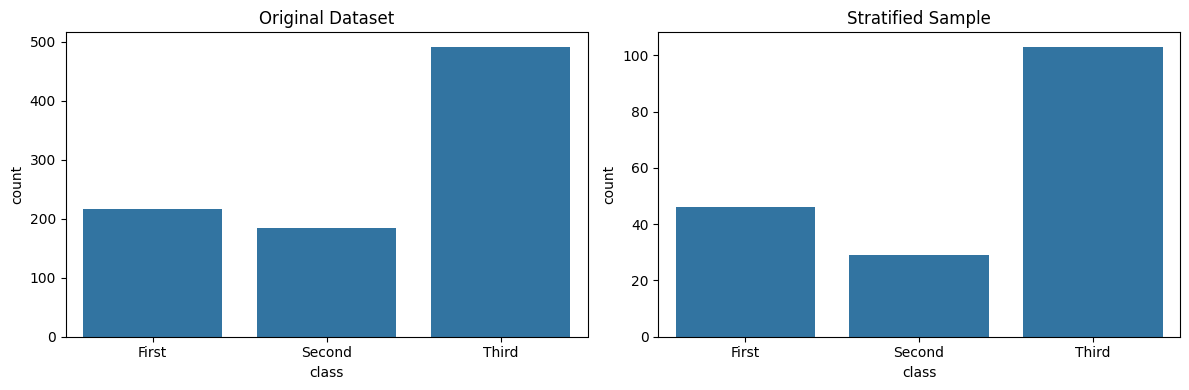

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(data=df, x="class", ax=axes[0])
axes[0].set_title("Original Dataset")

sns.countplot(data=stratified_sample, x="class", ax=axes[1])
axes[1].set_title("Stratified Sample")

plt.tight_layout()
plt.show()

# `Systematic Sampling`

In systematic sampling, we select every kth observation after choosing a random starting position.

Formula:
  k=N/n

Where:
- \(N\) = Population size
- \(n\) = Required sample size
- \(k\) = Sampling interval

In [9]:
N = len(df)
n = 100

k = N // n

start = np.random.default_rng(42).integers(0, k)

indices = np.arange(start, N, k)[:n]

systematic_sample = df.iloc[indices]

display(systematic_sample.head())

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
8,1,3,female,27.0,0,2,11.1333,S,Third,woman,False,NaN,Southampton,yes,False
16,0,3,male,2.0,4,1,29.1250,Q,Third,child,False,NaN,Queenstown,no,False
24,0,3,female,8.0,3,1,21.0750,S,Third,child,False,NaN,Southampton,no,False
32,1,3,female,NaN,0,0,7.7500,Q,Third,woman,False,NaN,Queenstown,yes,True


In [ ]:
plt.figure(figsize=(12, 4))

plt.scatter(
    systematic_sample.index,
    systematic_sample["age"]
)

plt.title("Systematic Sampling")
plt.xlabel("Original Row Index")
plt.ylabel("Age")
plt.show()

# `Cluster Sampling`

In [13]:
clusters = df["pclass"].unique()

rng = np.random.default_rng(42)

selected_clusters = rng.choice(
    clusters,
    size=2,
    replace=False
)

cluster_sample = df[
    df["pclass"].isin(selected_clusters)
]

print("Selected clusters:", selected_clusters)
print("Sample size:", len(cluster_sample))

Selected clusters: [3 2]
Sample size: 675


In [14]:
plt.figure(figsize=(12, 5))

cluster_sample["native-country"].value_counts().plot(
    kind="bar"
)

plt.title("Observations from Selected Clusters")
plt.xlabel("Country")
plt.ylabel("Number of Observations")
plt.xticks(rotation=90)
plt.show()

KeyError: 'native-country'

<Figure size 1200x500 with 0 Axes>

# `Compare all four sampling techniques`

In [ ]:
comparison = pd.DataFrame({
    "Sampling Method": [
        "Simple Random",
        "Stratified",
        "Systematic",
        "Cluster"
    ],
    "Sample Size": [
        len(random_sample),
        len(stratified_sample),
        len(systematic_sample),
        len(cluster_sample)
    ],
    "Percentage of Population": [
        len(random_sample) / len(df) * 100,
        len(stratified_sample) / len(df) * 100,
        len(systematic_sample) / len(df) * 100,
        len(cluster_sample) / len(df) * 100
    ]
})

display(comparison.round(2))

# `Part 2 — Train-Test Splitting`

In [15]:
#Basic Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print(X_train.shape, X_test.shape)

(712, 14) (179, 14)


In [16]:
#Stratified Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Train Distribution:")
print(y_train.value_counts(normalize=True))

print("\nTest Distribution:")
print(y_test.value_counts(normalize=True))

Train Distribution:
survived
0    0.616573
1    0.383427
Name: proportion, dtype: float64

Test Distribution:
survived
0    0.614525
1    0.385475
Name: proportion, dtype: float64


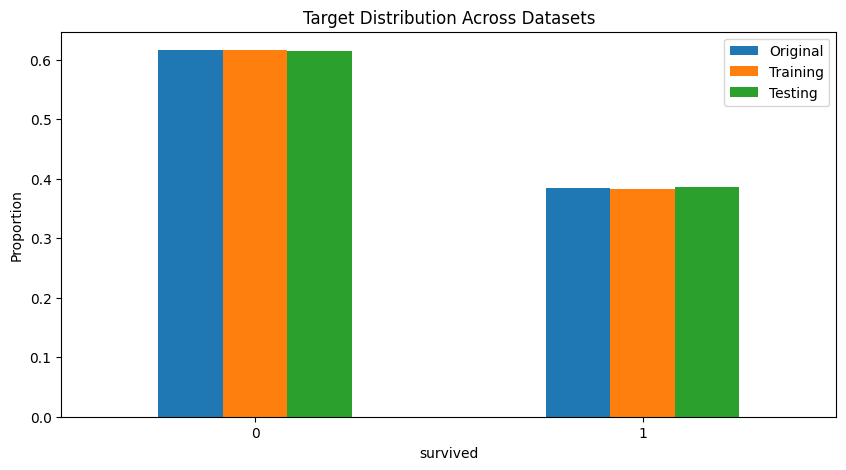

In [17]:
distribution = pd.DataFrame({
    "Original": y.value_counts(normalize=True),
    "Training": y_train.value_counts(normalize=True),
    "Testing": y_test.value_counts(normalize=True)
})

distribution.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Target Distribution Across Datasets")
plt.ylabel("Proportion")
plt.xticks(rotation=0)
plt.show()

In [18]:
#Train-Validation-Test Split
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp,
    test_size=0.2,
    random_state=42,
    stratify=y_temp
)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (569, 14)
Validation: (143, 14)
Test: (179, 14)


In [ ]:
#Group-Based Train-Test Split
from sklearn.model_selection import GroupShuffleSplit

# Artificial customer groups for demonstration
rng = np.random.default_rng(42)

groups = np.arange(len(df)) // 3

# Randomize group assignments across rows
groups = rng.permutation(groups)

gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    gss.split(X, y, groups=groups)
)

X_train_group = X.iloc[train_idx]
X_test_group = X.iloc[test_idx]

y_train_group = y.iloc[train_idx]
y_test_group = y.iloc[test_idx]

train_groups = set(groups[train_idx])
test_groups = set(groups[test_idx])

print("Training:", X_train_group.shape)
print("Testing:", X_test_group.shape)

print("Overlapping groups:", len(train_groups & test_groups))